In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import polars as pl
import torch
from sklearn.metrics import roc_auc_score
from matplotlib.lines import Line2D

import load_db as db
import sequences as seq
import cnn
import evaluation as ev
import plotting_functions as pltfun

In [2]:
data_dir = 'data'
image_dir = 'images'

# 1D CNN in PyTorch

In [3]:
# instead of the manual feature extraction we did with the ML pipeline, let's make a model that sees the light curve itself. does the shape information 
# allow the CNN to catch events better than the logistic regression/TS fitter?
# we'll basically be reproducing the steps in the ML pipeline but using a CNN, and let's use the SQL database why not

# we need to solve the problem of the CNN expecting evenly spaced input, as the actual data varies in n_obs, cadence, and duration. we can do this in a 
# number of ways but i think the two options are:
# 
#   1: input the data as-is, in the form of SNR and gap (time between observations) arrays. the neighbor to each data point can have different gap 
#      times, so the CNN will have to read the SNR and gap together
# 
#   2: bin the observation times (e.g. 2 hours), and zero-pad the empty bins so that each neighbor has the same time difference. there will be a lot
#      of zeroes in the data this way, but the light curves will have an identical cadence. binning will have to be a balance between not obfuscating 
#      the data (a bin too long can miss features in back-to-back-to-back observations) and not introducing a million empty data points
# 
# i think the first solution should be fine for this, as the accuracy of the data is probably more important. comparing the binning methodcould be a 
# future test pending how in-depth we want to go.

In [4]:
with db.connect() as conn:
    windows = seq.fetch_window_observations(conn)
    dataset_rows = db.query_df(conn, 'SELECT * FROM dataset ORDER BY label, window_id, inj_id')

# the SQL check only compared stored fit results. the injected light curves were never saved,
# so rebuild them here and confirm refitting gives back the same TS
check = seq.check_rebuild(dataset_rows, windows)
print(check.group_by('source').agg(
    pl.len().alias('N'),
    pl.col('abs_diff').max().alias('max_abs_diff'),
    (pl.col('abs_diff') / pl.col('ts').abs()).max().alias('max_rel_diff'),
))

# build and save the sequences, with a table saying which row is which
window_sequences = seq.build_sequences(dataset_rows, windows)
print(window_sequences.shape)
np.save('data/sequences.npy', window_sequences)
dataset_rows.select(
    'window_id', 'gaia_id', 'window_start', 'inj_id', 'source', 'label'
).write_parquet('data/sequences_meta.parquet')

  0%|          | 0/200 [00:00<?, ?it/s]

shape: (2, 4)
┌───────────┬─────┬──────────────┬──────────────┐
│ source    ┆ N   ┆ max_abs_diff ┆ max_rel_diff │
│ ---       ┆ --- ┆ ---          ┆ ---          │
│ str       ┆ u32 ┆ f64          ┆ f64          │
╞═══════════╪═════╪══════════════╪══════════════╡
│ quiescent ┆ 100 ┆ 0.0          ┆ 0.0          │
│ injection ┆ 100 ┆ 0.0          ┆ 0.0          │
└───────────┴─────┴──────────────┴──────────────┘


  0%|          | 0/21483 [00:00<?, ?it/s]

(21483, 5, 33)


### training loop

In [5]:
# three 1D convolution layers, each filter 3 observations wide (32, 32, 64 filters), with ReLU between them.
# the filters learn shapes like a rapid rise/decay or a broad bump in the lc. masked max pooling keeps each
# filter's strongest response anywhere in the window while ignoring the padding
# 
# first we'll do the same star-group folding as in the ML notebook and validate hte output

In [6]:
window_sequences = np.load('data/sequences.npy')
sequence_rows = pl.read_parquet('data/sequences_meta.parquet')
scores = pl.read_parquet('data/scores.parquet')

# same star-grouped folds as the ML models
folds = cnn.star_folds(scores)
sequence_rows = sequence_rows.with_columns(pl.col('gaia_id').replace_strict(folds).alias('fold'))
print(sequence_rows.group_by('fold').agg(
    pl.len().alias('N'),
    pl.col('gaia_id').n_unique().alias('N_stars'),
    pl.col('label').mean().alias('positive_fraction'),
).sort('fold'))
print(scores.group_by('fold').agg(pl.len().alias('N')).sort('fold'))

# the untrained model runs, and extra padding doesn't change its output
torch.manual_seed(100)
model = cnn.FlareCNN()
model.eval()
print('parameters:', sum(p.numel() for p in model.parameters()))

batch = torch.from_numpy(window_sequences[:256])
extra_padding = torch.nn.functional.pad(batch, (0, 20)) # 20 more zero columns
with torch.no_grad():
    max_change = (model(batch) - model(extra_padding)).abs().max().item()
print('max output change from extra padding:', max_change)

shape: (5, 4)
┌──────┬──────┬─────────┬───────────────────┐
│ fold ┆ N    ┆ N_stars ┆ positive_fraction │
│ ---  ┆ ---  ┆ ---     ┆ ---               │
│ i64  ┆ u32  ┆ u32     ┆ f64               │
╞══════╪══════╪═════════╪═══════════════════╡
│ 0    ┆ 4215 ┆ 13      ┆ 0.502966          │
│ 1    ┆ 4233 ┆ 13      ┆ 0.502953          │
│ 2    ┆ 4481 ┆ 14      ┆ 0.49788           │
│ 3    ┆ 4327 ┆ 13      ┆ 0.507049          │
│ 4    ┆ 4227 ┆ 13      ┆ 0.510764          │
└──────┴──────┴─────────┴───────────────────┘
shape: (5, 2)
┌──────┬──────┐
│ fold ┆ N    │
│ ---  ┆ ---  │
│ i64  ┆ u32  │
╞══════╪══════╡
│ 0    ┆ 4215 │
│ 1    ┆ 4233 │
│ 2    ┆ 4481 │
│ 3    ┆ 4327 │
│ 4    ┆ 4227 │
└──────┴──────┘
parameters: 11937
max output change from extra padding: 0.0


In [7]:
# now we'll do the out-of-fold scores along with the mirrored quiescent window scores

In [8]:
cnn_scores, cnn_history = cnn.cross_validate(window_sequences, sequence_rows)

# out-of-fold AUC per fold, comparable with the ~0.97 of the other models
cnn_auc = pl.DataFrame([
    {'fold': fold, 'N': group.height, 'auc': roc_auc_score(group['label'], group['cnn_score'])}
    for (fold,), group in cnn_scores.group_by('fold')
]).sort('fold')
print(cnn_auc)

cnn_scores.write_parquet('data/cnn_scores.parquet')
cnn_history.write_parquet('data/cnn_history.parquet')

fold 0: 19 epochs, best epoch 13, val loss 0.1669, N_train 14624, N_val 2644, 8.7 s
fold 1: 23 epochs, best epoch 17, val loss 0.1653, N_train 14749, N_val 2501, 8.6 s
fold 2: 18 epochs, best epoch 12, val loss 0.1661, N_train 14396, N_val 2606, 6.6 s
fold 3: 15 epochs, best epoch 9, val loss 0.1577, N_train 14663, N_val 2493, 5.5 s
fold 4: 22 epochs, best epoch 16, val loss 0.1724, N_train 14717, N_val 2539, 7.8 s
shape: (5, 3)
┌──────┬──────┬──────────┐
│ fold ┆ N    ┆ auc      │
│ ---  ┆ ---  ┆ ---      │
│ i64  ┆ i64  ┆ f64      │
╞══════╪══════╪══════════╡
│ 0    ┆ 4215 ┆ 0.977703 │
│ 1    ┆ 4233 ┆ 0.977345 │
│ 2    ┆ 4481 ┆ 0.977955 │
│ 3    ┆ 4327 ┆ 0.976015 │
│ 4    ┆ 4227 ┆ 0.974188 │
└──────┴──────┴──────────┘


In [9]:
# validation losses have a tight range. per fold AUC is slightly higher than the log and gbm methods; this suggests the light curves
# themselves carry some more information than the summary features used in the ML methods did. this isn't definitive proof, we'll
# need to look at recall on mirrored noise (logistic -> 0.808, TS-> 0.715-0.796) and see if the CNN outperforms here
# 
# we'll also check:
# 
#   - leakage: do noise window scores trend with observation count? we want to make sure masking or the window length
#     don't give the model information it shouldn't have
# 
#   - disagreement analysis: which injections only the CNN catches. the idea is that shape information should help for longer
#     duration flares (more observations to have a shape), so longer flares should have better detection metrics (?? maybe?)
# 
#   - spectral prior: detection rate by true spectral index. this is where GBM failed
# 
#   - fixed alpha test: inject at fixed spectral indices (same total SNR) and check if detection depends on spectrum
# 
#   - real events: can we recover the actual real life flares?
# 
#   - robustness: try different layer configurations; is 32,32,64 ideal?

In [11]:
feature_columns = ['ts', 'fwhm_d', 'snr_amp_95', 'snr_amp_150', 'n_3sigma_both']
dataset_rows = pl.read_parquet('data/dataset.parquet')
scores = pl.read_parquet('data/scores.parquet')
mirrored = pl.read_parquet('data/mirrored_negatives.parquet')
cnn_scores = pl.read_parquet('data/cnn_scores.parquet')

# scores.parquet has no inj_id or features, but its rows are in dataset.parquet's order
for column in ['gaia_id', 'window_start', 'label']:
    assert (scores[column] == dataset_rows[column]).all(), column
scores = scores.with_columns(dataset_rows.select(*feature_columns))
assert (ev.ts_scores(scores.drop('ts_positive_score', 'ts_positive_fwhm_score', 'ts_positive_fwhm_pixel_score'))
        ['ts_positive_fwhm_pixel_score'] == scores['ts_positive_fwhm_pixel_score']).all()

# attach CNN scores: windows by (star, rounded start), injections by inj_id
window_key = ['gaia_id', pl.col('window_start').round(6).alias('window_key')]
cnn_windows = cnn_scores.filter(pl.col('source') == 'quiescent').select(
    *window_key, 'cnn_score', 'cnn_mirrored_score')
cnn_injections = cnn_scores.filter(pl.col('source') == 'injection').select(
    pl.col('inj_id').cast(pl.Int64), 'cnn_score')

noise = (mirrored.with_columns(pl.col('window_start').round(6).alias('window_key'))
         .join(cnn_windows.select('gaia_id', 'window_key', pl.col('cnn_mirrored_score').alias('cnn_score')),
               on=['gaia_id', 'window_key'], how='left'))
positives = (scores.filter(pl.col('label') == 1)
             .with_columns(pl.col('inj_id').cast(pl.Int64))
             .join(cnn_injections, on='inj_id', how='left'))
print(f"noise {noise.height}, null cnn {noise['cnn_score'].null_count()}; "
      f"positives {positives.height}, null cnn {positives['cnn_score'].null_count()}")

# bootstrap, same settings as before
methods = ['ts_positive_fwhm_pixel_score', 'ts_positive_fwhm_score', 'ts_positive_score',
           'logistic_score', 'gbm_score', 'gbm_no_ts_score', 'cnn_score']
fpr_levels = (0, 1e-4, 1e-3)
full_recall, boot_recall = ev.bootstrap_recall(positives, noise, methods, fpr_levels)

with pl.Config(tbl_rows=-1):
    print(ev.recall_table(full_recall, boot_recall, methods, fpr_levels))
    print('cnn - logistic')
    print(ev.paired_difference(full_recall, boot_recall, methods, 'cnn_score', 'logistic_score', fpr_levels))
    print('cnn - ts_positive')
    print(ev.paired_difference(full_recall, boot_recall, methods, 'cnn_score', 'ts_positive_score', fpr_levels))

noise 10650, null cnn 0; positives 10833, null cnn 0


  0%|          | 0/1000 [00:00<?, ?it/s]

shape: (21, 5)
┌────────┬────────────────────────┬──────────┬──────────┬──────────┐
│ fpr    ┆ method                 ┆ recall   ┆ ci_low   ┆ ci_high  │
│ ---    ┆ ---                    ┆ ---      ┆ ---      ┆ ---      │
│ f64    ┆ str                    ┆ f64      ┆ f64      ┆ f64      │
╞════════╪════════════════════════╪══════════╪══════════╪══════════╡
│ 0.0    ┆ ts_positive_fwhm_pixel ┆ 0.715222 ┆ 0.707498 ┆ 0.725566 │
│ 0.0    ┆ ts_positive_fwhm       ┆ 0.787317 ┆ 0.780462 ┆ 0.835504 │
│ 0.0    ┆ ts_positive            ┆ 0.795532 ┆ 0.788268 ┆ 0.830827 │
│ 0.0    ┆ logistic               ┆ 0.808363 ┆ 0.800831 ┆ 0.857403 │
│ 0.0    ┆ gbm                    ┆ 0.787317 ┆ 0.779609 ┆ 0.814073 │
│ 0.0    ┆ gbm_no_ts              ┆ 0.795255 ┆ 0.788209 ┆ 0.810182 │
│ 0.0    ┆ cnn                    ┆ 0.78704  ┆ 0.779885 ┆ 0.836602 │
│ 0.0001 ┆ ts_positive_fwhm_pixel ┆ 0.717161 ┆ 0.708179 ┆ 0.725922 │
│ 0.0001 ┆ ts_positive_fwhm       ┆ 0.798763 ┆ 0.782853 ┆ 0.838846 │
│ 0.0001 ┆ ts_posit

In [12]:
# well, the CNN does not outperform logistic regression... so far. could be we're trying to complicate something simple. could be an issue
# with how we've setup this experiment and all the assumptions we've made (injecting simple gaussian flares, gaussian fits, a lot of possibilites)
# 
# let's do a couple of checks:
# 
#   - noise windows: which ones set the CNN threshold? if it's bright outliers then that should be a fix: the CNN is reacting to spikes
#     that the gaussian fit is discounting
# 
#   - seeding: maybe we're unlucky. let's try a few others

### noise tail

shape: (10, 13)
┌──────────┬───────────────┬─────────────────────┬──────────────┬───────────┬────────────────┬───────────┬───────────┬────────────┬─────────────┬───────────────┬──────────┬────────┐
│ cnn_rank ┆ logistic_rank ┆ gaia_id             ┆ window_start ┆ cnn_score ┆ logistic_score ┆ ts        ┆ fwhm_d    ┆ snr_amp_95 ┆ snr_amp_150 ┆ n_3sigma_both ┆ peak_snr ┆ n_good │
│ ---      ┆ ---           ┆ ---                 ┆ ---          ┆ ---       ┆ ---            ┆ ---       ┆ ---       ┆ ---        ┆ ---         ┆ ---           ┆ ---      ┆ ---    │
│ u32      ┆ u32           ┆ str                 ┆ f64          ┆ f64       ┆ f64            ┆ f64       ┆ f64       ┆ f64        ┆ f64         ┆ i64           ┆ f64      ┆ i64    │
╞══════════╪═══════════════╪═════════════════════╪══════════════╪═══════════╪════════════════╪═══════════╪═══════════╪════════════╪═════════════╪═══════════════╪══════════╪════════╡
│ 1        ┆ 1             ┆ 6559052816392332288 ┆ 59700.782153 ┆ 0.975401

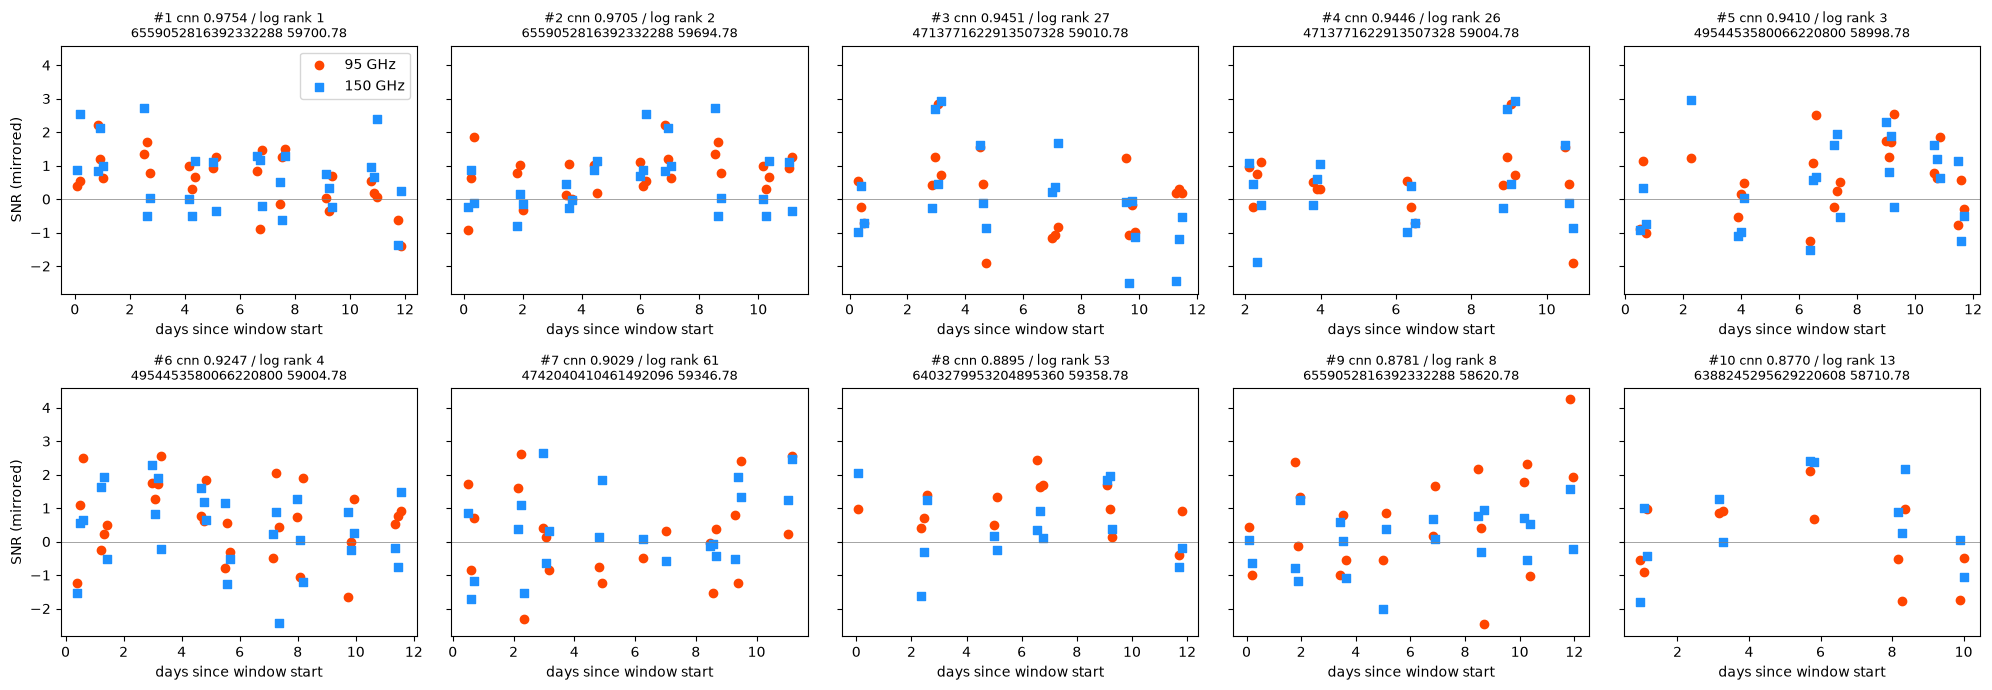

In [13]:
# ZFP is the CNN's highest score on mirrored noise. let's look at the top windows and their logistic score to see if we can make sense of it

import matplotlib.pyplot as plt

# rank every mirrored noise window by CNN and by logistic score (1 = most flare-like)
noise_ranked = noise.with_columns(
    pl.col('cnn_score').rank('ordinal', descending=True).alias('cnn_rank'),
    pl.col('logistic_score').rank('ordinal', descending=True).alias('logistic_rank'),
).sort('cnn_rank')

with pl.Config(tbl_cols=-1, tbl_width_chars=250):
    print(noise_ranked.head(10).select(
        'cnn_rank', 'logistic_rank', 'gaia_id', 'window_start', 'cnn_score', 'logistic_score',
        'ts', 'fwhm_d', 'snr_amp_95', 'snr_amp_150', 'n_3sigma_both', 'peak_snr', 'n_good'))

# recall when the k highest-scoring noise windows are let through
positive_cnn, positive_logistic = positives['cnn_score'].to_numpy(), positives['logistic_score'].to_numpy()
noise_cnn, noise_logistic = noise['cnn_score'].to_numpy(), noise['logistic_score'].to_numpy()
print(pl.DataFrame([
    {'N_noise_allowed': k,
     'cnn_recall': ev.recall_at_fpr(positive_cnn, noise_cnn, k / noise.height),
     'logistic_recall': ev.recall_at_fpr(positive_logistic, noise_logistic, k / noise.height)}
    for k in range(11)
]))

# what the CNN sees in its top 10 noise windows (mirrored, so these are the sign-flipped data)
sequence_keys = sequence_rows.with_row_index('row').filter(pl.col('source') == 'quiescent').select(
    'row', 'gaia_id', pl.col('window_start').round(6).alias('window_key'))
top_rows = (noise_ranked.head(10)
            .with_columns(pl.col('window_start').round(6).alias('window_key'))
            .join(sequence_keys, on=['gaia_id', 'window_key'], how='left')
            .sort('cnn_rank'))
top_sequences = cnn.mirror(window_sequences[top_rows['row'].to_numpy()])

fig, axes = plt.subplots(2, 5, figsize=(20, 7), sharey=True)
for ax, sequence, info in zip(axes.flat, top_sequences, top_rows.iter_rows(named=True)):
    real = sequence[4] > 0
    t_days = sequence[2][real] * 12
    ax.scatter(t_days, sequence[0][real], marker='o', color='orangered', label='95 GHz')
    ax.scatter(t_days, sequence[1][real], marker='s', color='dodgerblue', label='150 GHz')
    ax.axhline(0, color='gray', lw=0.5)
    ax.set_title(f"#{info['cnn_rank']} cnn {info['cnn_score']:.4f} / log rank {info['logistic_rank']}\n"
                 f"{info['gaia_id']} {info['window_start']:.2f}", fontsize=9)
    ax.set_xlabel('days since window start')
axes[0, 0].set_ylabel('SNR (mirrored)')
axes[1, 0].set_ylabel('SNR (mirrored)')
axes[0, 0].legend()
fig.tight_layout()
plt.show()

In [14]:
# CNN flares 3 and 4 (same event in different windows) are in disagreement, looks like the CNN picks up on abrupt short fluctuations in both bands.
# for k noise allowed, looks like logistic outperforms everywhere, suggesting this isn't a one-off fluke

## seed testing

In [15]:
# retrain with different seeds; seed 100 should reproduce the run above
seeds = [100, 101, 102, 103, 104]
seed_scores = {}
seed_rows = []
for seed in seeds:
    seed_cnn_scores, _ = cnn.cross_validate(window_sequences, sequence_rows, seed=seed)
    seed_scores[seed] = seed_cnn_scores
    positive_scores = seed_cnn_scores.filter(pl.col('label') == 1)['cnn_score'].to_numpy()
    noise_scores = seed_cnn_scores.filter(pl.col('source') == 'quiescent')['cnn_mirrored_score'].to_numpy()
    seed_rows.append({
        'seed': seed,
        'auc': roc_auc_score(seed_cnn_scores['label'], seed_cnn_scores['cnn_score']),
        'recall_fpr_0': ev.recall_at_fpr(positive_scores, noise_scores, 0),
        'recall_fpr_1e-3': ev.recall_at_fpr(positive_scores, noise_scores, 1e-3),
    })

# ensemble: average the five models' scores for each window (rows are in the same order every run)
ensemble = seed_scores[seeds[0]].select('label', 'source').with_columns(
    pl.mean_horizontal([seed_scores[s]['cnn_score'] for s in seeds]).alias('cnn_score'),
    pl.mean_horizontal([seed_scores[s]['cnn_mirrored_score'] for s in seeds]).alias('cnn_mirrored_score'),
)
positive_scores = ensemble.filter(pl.col('label') == 1)['cnn_score'].to_numpy()
noise_scores = ensemble.filter(pl.col('source') == 'quiescent')['cnn_mirrored_score'].to_numpy()
seed_rows.append({
    'seed': None,
    'auc': roc_auc_score(ensemble['label'], ensemble['cnn_score']),
    'recall_fpr_0': ev.recall_at_fpr(positive_scores, noise_scores, 0),
    'recall_fpr_1e-3': ev.recall_at_fpr(positive_scores, noise_scores, 1e-3),
})
print(pl.DataFrame(seed_rows)) # last row (seed null) is the 5-seed ensemble

fold 0: 19 epochs, best epoch 13, val loss 0.1669, N_train 14624, N_val 2644, 7.2 s
fold 1: 23 epochs, best epoch 17, val loss 0.1653, N_train 14749, N_val 2501, 8.6 s
fold 2: 18 epochs, best epoch 12, val loss 0.1661, N_train 14396, N_val 2606, 6.6 s
fold 3: 15 epochs, best epoch 9, val loss 0.1577, N_train 14663, N_val 2493, 5.5 s
fold 4: 22 epochs, best epoch 16, val loss 0.1724, N_train 14717, N_val 2539, 7.6 s
fold 0: 18 epochs, best epoch 12, val loss 0.1654, N_train 14638, N_val 2630, 6.5 s
fold 1: 23 epochs, best epoch 17, val loss 0.1832, N_train 14683, N_val 2567, 7.6 s
fold 2: 19 epochs, best epoch 13, val loss 0.1699, N_train 14437, N_val 2565, 6.3 s
fold 3: 18 epochs, best epoch 12, val loss 0.1631, N_train 14560, N_val 2596, 6.2 s
fold 4: 10 epochs, best epoch 4, val loss 0.1666, N_train 14670, N_val 2586, 3.4 s
fold 0: 8 epochs, best epoch 2, val loss 0.1638, N_train 14720, N_val 2548, 2.8 s
fold 1: 11 epochs, best epoch 5, val loss 0.1861, N_train 14632, N_val 2618, 3.8

In [16]:
# ok! so we were unlucky with seed 100, but not really by much. the most sound method is to compare to the ensemble to smooth over any luck issues. 
# for the ensemble, AUC barely moves: it's the probability that a randomly chosen positive scores higher than a randomly chosen noise window. it
# asks "how well does it rank in general?" where ZFP recall asks "how many flares can it detect without a single noise detection?", so it doesn't tell
# us the full picture.
# the ensemble matches the logistic regression at ZFP within the seed scatter. at 1e-3 it's consistently a little bit lower (logistic=0.859)
# 
# let's bootstrap the ensemble and do further testing

In [20]:
# ensemble: per-window mean of the five seeds' scores; this is "The CNN" from here on
key_columns = ['gaia_id', 'window_start', 'window_id', 'inj_id', 'source', 'label', 'fold']
cnn_ensemble = seed_scores[seeds[0]].select(key_columns).with_columns(
    pl.mean_horizontal([seed_scores[s]['cnn_score'] for s in seeds]).alias('cnn_score'),
    pl.mean_horizontal([seed_scores[s]['cnn_mirrored_score'] for s in seeds]).alias('cnn_mirrored_score'),
)
cnn_ensemble.write_parquet('data/cnn_scores.parquet')

# keep every seed's scores on record
pl.concat([
    seed_scores[s].with_columns(pl.lit(s).alias('seed')) for s in seeds
]).write_parquet('data/cnn_scores_by_seed.parquet')

print(cnn_ensemble.select(
    pl.col('cnn_score').null_count().alias('N_null_score'),
    pl.col('cnn_mirrored_score').is_not_null().sum().alias('N_mirrored'),
))

shape: (1, 2)
┌──────────────┬────────────┐
│ N_null_score ┆ N_mirrored │
│ ---          ┆ ---        │
│ u32          ┆ u32        │
╞══════════════╪════════════╡
│ 0            ┆ 10650      │
└──────────────┴────────────┘


In [24]:
feature_columns = ['ts', 'fwhm_d', 'snr_amp_95', 'snr_amp_150', 'n_3sigma_both']
dataset_rows = pl.read_parquet('data/dataset.parquet')
scores = pl.read_parquet('data/scores.parquet')
mirrored = pl.read_parquet('data/mirrored_negatives.parquet')
cnn_scores = pl.read_parquet('data/cnn_scores.parquet')

# scores.parquet has no inj_id or features, but its rows are in dataset.parquet's order
for column in ['gaia_id', 'window_start', 'label']:
    assert (scores[column] == dataset_rows[column]).all(), column
scores = scores.with_columns(dataset_rows.select(*feature_columns))

# attach CNN scores: windows by (star, rounded start), injections by inj_id
window_key = ['gaia_id', pl.col('window_start').round(6).alias('window_key')]
cnn_windows = cnn_scores.filter(pl.col('source') == 'quiescent').select(
    *window_key, 'cnn_score', 'cnn_mirrored_score')
cnn_injections = cnn_scores.filter(pl.col('source') == 'injection').select(
    pl.col('inj_id').cast(pl.Int64), 'cnn_score')

noise = (mirrored.with_columns(pl.col('window_start').round(6).alias('window_key'))
         .join(cnn_windows.select('gaia_id', 'window_key', pl.col('cnn_mirrored_score').alias('cnn_score')),
               on=['gaia_id', 'window_key'], how='left'))
positives = (scores.filter(pl.col('label') == 1)
             .with_columns(pl.col('inj_id').cast(pl.Int64))
             .join(cnn_injections, on='inj_id', how='left'))
print(f"noise {noise.height}, null cnn {noise['cnn_score'].null_count()}; "
      f"positives {positives.height}, null cnn {positives['cnn_score'].null_count()}")

# bootstrap, same settings as before
methods = ['ts_positive_fwhm_pixel_score', 'ts_positive_fwhm_score', 'ts_positive_score',
           'logistic_score', 'gbm_score', 'gbm_no_ts_score', 'cnn_score']
fpr_levels = (0, 1e-4, 1e-3)
full_recall, boot_recall = ev.bootstrap_recall(positives, noise, methods, fpr_levels)

with pl.Config(tbl_rows=-1):
    print(ev.recall_table(full_recall, boot_recall, methods, fpr_levels))
    print('cnn - logistic')
    print(ev.paired_difference(full_recall, boot_recall, methods, 'cnn_score', 'logistic_score', fpr_levels))
    print('cnn - ts_positive')
    print(ev.paired_difference(full_recall, boot_recall, methods, 'cnn_score', 'ts_positive_score', fpr_levels))

noise 10650, null cnn 0; positives 10833, null cnn 0


  0%|          | 0/1000 [00:00<?, ?it/s]

shape: (21, 5)
┌────────┬────────────────────────┬──────────┬──────────┬──────────┐
│ fpr    ┆ method                 ┆ recall   ┆ ci_low   ┆ ci_high  │
│ ---    ┆ ---                    ┆ ---      ┆ ---      ┆ ---      │
│ f64    ┆ str                    ┆ f64      ┆ f64      ┆ f64      │
╞════════╪════════════════════════╪══════════╪══════════╪══════════╡
│ 0.0    ┆ ts_positive_fwhm_pixel ┆ 0.715222 ┆ 0.707498 ┆ 0.725566 │
│ 0.0    ┆ ts_positive_fwhm       ┆ 0.787317 ┆ 0.780462 ┆ 0.835504 │
│ 0.0    ┆ ts_positive            ┆ 0.795532 ┆ 0.788268 ┆ 0.830827 │
│ 0.0    ┆ logistic               ┆ 0.808363 ┆ 0.800831 ┆ 0.857403 │
│ 0.0    ┆ gbm                    ┆ 0.787317 ┆ 0.779609 ┆ 0.814073 │
│ 0.0    ┆ gbm_no_ts              ┆ 0.795255 ┆ 0.788209 ┆ 0.810182 │
│ 0.0    ┆ cnn                    ┆ 0.803194 ┆ 0.7962   ┆ 0.82898  │
│ 0.0001 ┆ ts_positive_fwhm_pixel ┆ 0.717161 ┆ 0.708179 ┆ 0.725922 │
│ 0.0001 ┆ ts_positive_fwhm       ┆ 0.798763 ┆ 0.782853 ┆ 0.838846 │
│ 0.0001 ┆ ts_posit

  0%|          | 0/1000 [00:00<?, ?it/s]

shape: (15, 5)
┌───────┬────────────────────────┬──────────┬──────────┬──────────┐
│ fpr   ┆ method                 ┆ recall   ┆ ci_low   ┆ ci_high  │
│ ---   ┆ ---                    ┆ ---      ┆ ---      ┆ ---      │
│ f64   ┆ str                    ┆ f64      ┆ f64      ┆ f64      │
╞═══════╪════════════════════════╪══════════╪══════════╪══════════╡
│ 0.0   ┆ cnn                    ┆ 0.803194 ┆ 0.7962   ┆ 0.82898  │
│ 0.0   ┆ gbm                    ┆ 0.787317 ┆ 0.779609 ┆ 0.814073 │
│ 0.0   ┆ logistic               ┆ 0.808363 ┆ 0.800831 ┆ 0.857403 │
│ 0.0   ┆ ts_positive_fwhm       ┆ 0.787317 ┆ 0.780462 ┆ 0.835504 │
│ 0.0   ┆ ts_positive_fwhm_pixel ┆ 0.715222 ┆ 0.707498 ┆ 0.725566 │
│ …     ┆ …                      ┆ …        ┆ …        ┆ …        │
│ 0.001 ┆ cnn                    ┆ 0.841134 ┆ 0.822104 ┆ 0.858314 │
│ 0.001 ┆ gbm                    ┆ 0.822764 ┆ 0.806406 ┆ 0.849431 │
│ 0.001 ┆ logistic               ┆ 0.859134 ┆ 0.824812 ┆ 0.869095 │
│ 0.001 ┆ ts_positive_fwhm       

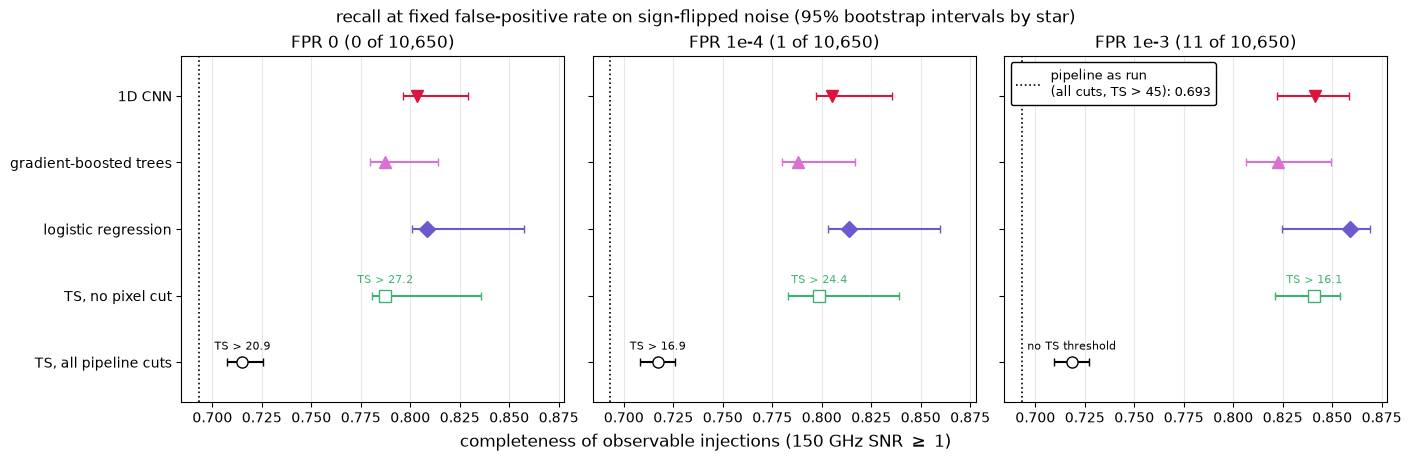

In [ ]:
# recall of observable injections at fixed false-positive rates on sign-flipped noise, with 95% bootstrap
# intervals (resampling stars). TS variants are re-tuned at each FPR level like the models, so their rows are
# named by cuts only. the pipeline as run (all cuts, TS > 45) is a fixed threshold, drawn as a reference line
summary_fpr_levels = (0, 1e-4, 1e-3)
summary_methods = {
    'cnn_score': pltfun.METHOD_STYLES['cnn'],
    'gbm_score': pltfun.METHOD_STYLES['gbm'],
    'logistic_score': pltfun.METHOD_STYLES['logistic'],
    'ts_positive_fwhm_score': {'label': 'TS, no pixel cut', 'color': 'mediumseagreen', 'marker': 's', 'open': True},
    'ts_positive_fwhm_pixel_score': {'label': 'TS, all pipeline cuts', 'color': 'black', 'marker': 'o', 'open': True},
}
missing = [m for m in summary_methods if m not in positives.columns or m not in noise.columns]
assert not missing, f"missing score columns: {missing}"

summary_full, summary_boot = ev.bootstrap_recall(positives, noise, list(summary_methods), summary_fpr_levels)
print(ev.recall_table(summary_full, summary_boot, list(summary_methods), summary_fpr_levels))
pipeline_as_run = (positives['ts_positive_fwhm_pixel_score'] > 45).mean()

y = np.arange(len(summary_methods))[::-1] # first method at the top
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharex=True, sharey=True, layout='constrained')
for i, (ax, fpr) in enumerate(zip(axes, summary_fpr_levels)):
    ax.axvline(pipeline_as_run, color='k', ls=':', lw=1.2, label=f"pipeline as run\n(all cuts, TS > 45): {pipeline_as_run:.3f}")
    for j, (method, style) in enumerate(summary_methods.items()):
        recall = summary_full[i, j]
        low, high = np.percentile(summary_boot[:, i, j], [2.5, 97.5])
        ax.errorbar(recall, y[j], xerr=[[recall - low], [high - recall]], fmt=style['marker'], ms=8, capsize=3,
                    color=style['color'], mfc='white' if style['open'] else style['color'])
        if method.startswith('ts_'):
            # the same threshold recall_at_fpr() uses: lets round(fpr * n) noise windows through
            threshold = np.sort(noise[method].to_numpy())[::-1][int(round(fpr * noise.height))]
            # fewer noise windows pass the cuts than the FPR allows: the cuts alone set the threshold
            threshold_label = 'no TS threshold' if threshold <= -1e8 else f"TS > {threshold:.1f}"
            ax.annotate(threshold_label, (recall, y[j]), xytext=(0, 9), textcoords='offset points',
                        ha='center', fontsize=8, color=style['color'])
    n_allowed = int(round(fpr * noise.height))
    fpr_label = '0' if fpr == 0 else f"1e{int(np.log10(fpr))}"
    ax.set_title(f"FPR {fpr_label} ({int(round(fpr * noise.height))} of {noise.height:,})")
    ax.grid(axis='x', alpha=0.3)
axes[0].set_yticks(y, labels=[style['label'] for style in summary_methods.values()])
axes[0].set_ylim(-0.6, len(summary_methods) - 0.4)
axes[-1].legend(loc='upper left', fontsize=9, edgecolor='k', framealpha=1)
fig.supxlabel('completeness of observable injections (150 GHz SNR $\\geq$ 1)')
fig.suptitle('recall at fixed false-positive rate on sign-flipped noise (95% bootstrap intervals by star)')
plt.savefig(f"{image_dir}/evaluation/recall_summary.png", dpi=150, bbox_inches='tight')

lowered threshold: TS > 27.19


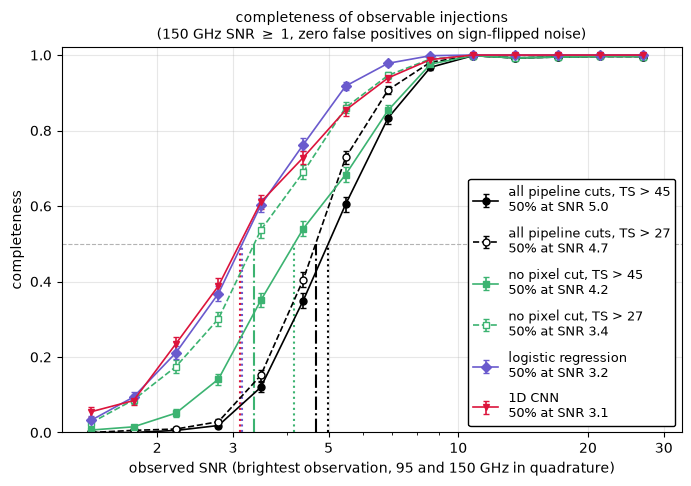

In [ ]:
# completeness of the observable injections vs observed SNR, same figure as in 01 plus the 1D CNN.
# the combined two-band observed SNR was computed and cached in 01
observed_snr_table = pl.read_parquet(f"{data_dir}/inj_observed_snr.parquet").select('inj_id', 'inj_max_obs_snr_combined')
curve_positives = positives.join(observed_snr_table, on='inj_id', how='left')
assert curve_positives['inj_max_obs_snr_combined'].null_count() == 0
assert curve_positives.height == positives.height

# zero-false-positive thresholds: the highest score on sign-flipped noise. TS is lowered to the
# no-pixel-cut version's threshold (~27), as in 01
curve_threshold = {column: noise[column].max() for column in ['ts_positive_fwhm_score', 'logistic_score', 'cnn_score']}
lowered_ts = curve_threshold['ts_positive_fwhm_score']
print(f"lowered threshold: TS > {lowered_ts:.2f}")

observed_snr = curve_positives['inj_max_obs_snr_combined'].to_numpy()
all_cuts_ts = curve_positives['ts_positive_fwhm_pixel_score'].to_numpy()
no_pixel_ts = curve_positives['ts_positive_fwhm_score'].to_numpy()
detected = {
    'ts_positive_fwhm_pixel_45': all_cuts_ts > 45,
    'ts_positive_fwhm_pixel_27': all_cuts_ts > lowered_ts,
    'ts_positive_fwhm_45': no_pixel_ts > 45,
    'ts_positive_fwhm_27': no_pixel_ts > lowered_ts,
    'logistic': curve_positives['logistic_score'].to_numpy() > curve_threshold['logistic_score'],
    'cnn': curve_positives['cnn_score'].to_numpy() > curve_threshold['cnn_score'],
}

# first bin (combined SNR 1-1.25) dropped: nearly empty, since combined SNR >= 150 GHz SNR >= 1
snr_bin_edges = np.geomspace(1, 30, 16)[1:]
snr_bin_centers = np.sqrt(snr_bin_edges[:-1] * snr_bin_edges[1:])

fig, ax = plt.subplots(figsize=(8, 5))
ax.axhline(0.5, color='0.7', ls='--', lw=0.8, zorder=0)
# lines between bins are the same linear interpolation (in log SNR) used to find the 50% crossing
for name, method_detected in detected.items():
    style = pltfun.METHOD_STYLES[name]
    fraction, error = ev.binned_completeness(method_detected, observed_snr, snr_bin_edges)
    half = ev.snr_at_half(fraction, snr_bin_centers)
    ax.errorbar(snr_bin_centers, fraction, yerr=error, fmt=style['marker'], ls='--' if style['open'] else '-',
                ms=5, lw=1.2, capsize=2, color=style['color'], mfc='white' if style['open'] else style['color'],
                label=f"{style['label']}\n50% at SNR {half:.1f}")
    # drop line at the 50% crossing: dot-dash for the lowered threshold, dotted otherwise
    ax.plot([half, half], [0, 0.5], color=style['color'], ls='-.' if style['open'] else ':', lw=1.5)
ax.set_xscale('log')
ax.set_xticks([2, 3, 5, 10, 20, 30], labels=['2', '3', '5', '10', '20', '30'])
ax.xaxis.set_minor_formatter(plt.NullFormatter()) # no labels on the minor log ticks
ax.set_xlim(1.2, 33)
ax.set_ylim(0, 1.02)
ax.set_xlabel('observed SNR (brightest observation, 95 and 150 GHz in quadrature)')
ax.set_ylabel('completeness')
ax.set_title('completeness of observable injections\n(150 GHz SNR $\\geq$ 1, zero false positives on sign-flipped noise)', fontsize=10)
ax.grid(alpha=0.3)
ax.legend(loc='lower right', fontsize=9, labelspacing=0.8, edgecolor='k', framealpha=1)
plt.savefig(f"{image_dir}/evaluation/completeness_vs_snr.png", dpi=150, bbox_inches='tight')

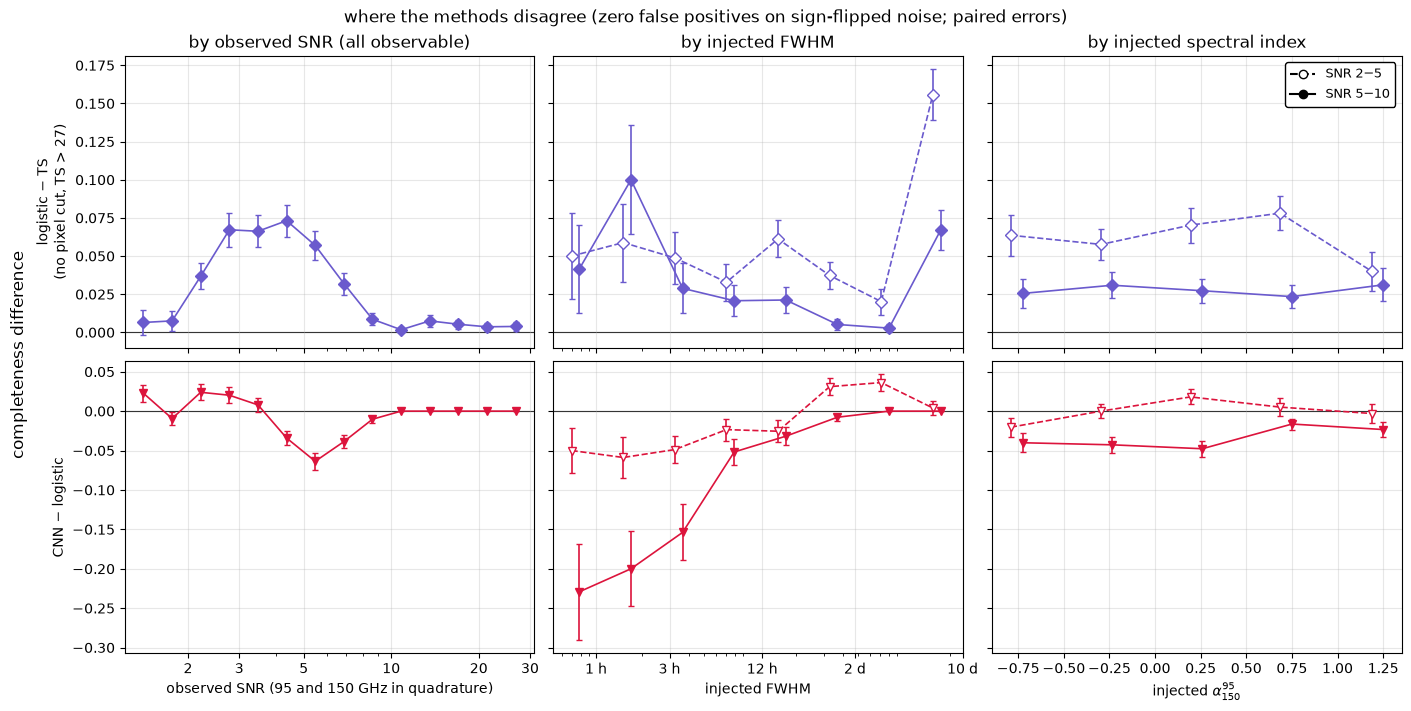

In [ ]:
# where do two methods disagree? completeness difference on the same injections (same zero-false-positive
# thresholds as the completeness curve) by observed SNR, injected FWHM and injected spectral index.
# top row: logistic regression - TS without the pixel cut; bottom row: CNN - logistic regression.
# errors are paired: only injections one method finds and the other misses add variance.
# FWHM and alpha panels are split into near threshold (SNR 2-5, open) and moderately bright (SNR 5-10, filled)
if 'inj_alpha' not in curve_positives.columns:
    alphas = pl.read_parquet(f"{data_dir}/dataset.parquet").filter(pl.col('label') == 1).select('inj_id', 'inj_alpha')
    curve_positives = curve_positives.join(alphas, on='inj_id', how='left', maintain_order='left')
assert curve_positives['inj_alpha'].null_count() == 0

fwhm_hours = curve_positives['inj_fwhm_d'].to_numpy() * 24
injected_alpha = curve_positives['inj_alpha'].to_numpy()

# (label, which injections, open marker)
snr_ranges = [
    ('SNR 2$-$5', (observed_snr >= 2) & (observed_snr < 5), True),
    ('SNR 5$-$10', (observed_snr >= 5) & (observed_snr < 10), False),
]

fwhm_bin_edges = np.geomspace(0.5, 240, 9) # hours: 30 min to 10 days
fwhm_bin_centers = np.sqrt(fwhm_bin_edges[:-1] * fwhm_bin_edges[1:])
alpha_bin_edges = np.array([-np.inf, -0.5, 0, 0.5, 1, np.inf])
alpha_bin_index = np.digitize(injected_alpha, alpha_bin_edges) - 1

def alpha_positions(in_sample):
    """Median injected alpha per bin (the open-ended bins have no center); NaN for empty bins."""
    positions = np.full(len(alpha_bin_edges) - 1, np.nan)
    for i in range(len(positions)):
        in_bin = in_sample & (alpha_bin_index == i)
        if in_bin.any():
            positions[i] = np.median(injected_alpha[in_bin])
    return positions

def draw_difference(ax, method_a, method_b, values, edges, positions, in_sample, is_open):
    """Binned completeness difference (method_a - method_b) with paired errors, in method_a's style."""
    style = pltfun.METHOD_STYLES[method_a]
    difference, error, _ = ev.binned_difference(detected[method_a][in_sample], detected[method_b][in_sample],
                                                values[in_sample], edges)
    ax.errorbar(positions, difference, yerr=error, fmt=style['marker'], ms=6, capsize=2, lw=1.2,
                ls='--' if is_open else '-', color=style['color'], mfc='white' if is_open else style['color'])

# (method a, method b, row label)
comparisons = [
    ('logistic', 'ts_positive_fwhm_27', 'logistic $-$ TS\n(no pixel cut, TS > 27)'),
    ('cnn', 'logistic', 'CNN $-$ logistic'),
]

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex='col', sharey='row', layout='constrained')
for row, (method_a, method_b, row_label) in enumerate(comparisons):
    # observed SNR: all observable injections
    draw_difference(axes[row, 0], method_a, method_b, observed_snr, snr_bin_edges, snr_bin_centers,
                    np.ones(len(observed_snr), dtype=bool), is_open=False)
    # FWHM and alpha: one series per SNR range, nudged apart so the error bars don't overlap
    for (_, in_range, is_open), nudge in zip(snr_ranges, [-1, 1]):
        draw_difference(axes[row, 1], method_a, method_b, fwhm_hours, fwhm_bin_edges,
                        fwhm_bin_centers * 1.06**nudge, in_range, is_open)
        draw_difference(axes[row, 2], method_a, method_b, injected_alpha, alpha_bin_edges,
                        alpha_positions(in_range) + 0.03 * nudge, in_range, is_open)
    for ax in axes[row]:
        ax.axhline(0, color='k', lw=0.8, zorder=0)
        ax.grid(alpha=0.3)
    axes[row, 0].set_ylabel(row_label)

axes[0, 0].set_title('by observed SNR (all observable)')
axes[0, 1].set_title('by injected FWHM')
axes[0, 2].set_title('by injected spectral index')
axes[1, 0].set_xscale('log')
axes[1, 0].set_xticks([2, 3, 5, 10, 20, 30], labels=['2', '3', '5', '10', '20', '30'])
axes[1, 0].xaxis.set_minor_formatter(plt.NullFormatter())
axes[1, 1].set_xscale('log')
axes[1, 1].set_xticks([1, 3, 12, 48, 240], labels=['1 h', '3 h', '12 h', '2 d', '10 d'])
axes[1, 1].xaxis.set_minor_formatter(plt.NullFormatter())
axes[1, 0].set_xlabel('observed SNR (95 and 150 GHz in quadrature)')
axes[1, 1].set_xlabel('injected FWHM')
axes[1, 2].set_xlabel('injected $\\alpha^{95}_{150}$')

range_handles = [Line2D([], [], color='k', marker='o', ls='--' if is_open else '-', mfc='white' if is_open else 'k',
                        label=label) for label, _, is_open in snr_ranges]
axes[0, 2].legend(handles=range_handles, loc='upper right', fontsize=9, edgecolor='k', framealpha=1)
fig.supylabel('completeness difference')
fig.suptitle('where the methods disagree (zero false positives on sign-flipped noise; paired errors)')
plt.savefig(f"{image_dir}/evaluation/disagreement.png", dpi=150, bbox_inches='tight')

In [ ]:
# ok this settles it. i'm happy here with the result that logistic regression (with the caveat of this setup including all assumptions yadda yadda) outperforms
# the cnn. just to be complete we can finish some parts of the remaining testing below, but i don't really think it's necessary. would be cool to be proved wrong though.

## extra tests For No Good Reason 
#### (there's actually a good reason)

#### leakage

In [ ]:
from scipy.stats import spearmanr

# do pure-noise scores climb with the number of observations in the window?
leakage = (noise
           .with_columns(pl.col('n_good').cut([10, 15, 20, 25]).alias('n_good_bin'))
           .group_by('n_good_bin')
           .agg(pl.len().alias('N'),
                pl.col('n_good').min().alias('n_good_min'),
                pl.col('cnn_score').mean().alias('cnn_mean'),
                pl.col('cnn_score').quantile(0.99).alias('cnn_q99'),
                pl.col('logistic_score').mean().alias('logistic_mean'),
                pl.col('logistic_score').quantile(0.99).alias('logistic_q99'))
           .sort('n_good_min'))
print(leakage)
for column in ['cnn_score', 'logistic_score']:
    rho, p_value = spearmanr(noise['n_good'], noise[column])
    print(f"{column}: spearman rho {rho:+.3f} (p {p_value:.1e})")

shape: (5, 7)
┌────────────┬──────┬────────────┬──────────┬──────────┬───────────────┬──────────────┐
│ n_good_bin ┆ N    ┆ n_good_min ┆ cnn_mean ┆ cnn_q99  ┆ logistic_mean ┆ logistic_q99 │
│ ---        ┆ ---  ┆ ---        ┆ ---      ┆ ---      ┆ ---           ┆ ---          │
│ enum       ┆ u32  ┆ i64        ┆ f64      ┆ f64      ┆ f64           ┆ f64          │
╞════════════╪══════╪════════════╪══════════╪══════════╪═══════════════╪══════════════╡
│ (-inf, 10] ┆ 631  ┆ 6          ┆ 0.083682 ┆ 0.557635 ┆ 0.070215      ┆ 0.3627       │
│ (10, 15]   ┆ 2173 ┆ 11         ┆ 0.092762 ┆ 0.71144  ┆ 0.093875      ┆ 0.545205     │
│ (15, 20]   ┆ 3515 ┆ 16         ┆ 0.10409  ┆ 0.714705 ┆ 0.106499      ┆ 0.61324      │
│ (20, 25]   ┆ 2604 ┆ 21         ┆ 0.114971 ┆ 0.730387 ┆ 0.122356      ┆ 0.639695     │
│ (25, inf]  ┆ 1727 ┆ 26         ┆ 0.110692 ┆ 0.673323 ┆ 0.116789      ┆ 0.565072     │
└────────────┴──────┴────────────┴──────────┴──────────┴───────────────┴──────────────┘
cnn_score: spearma

/tmp/ipykernel_501752/423773785.py:5: DeprecationWarning: `cut` is deprecated; use `bin_intervals` instead
  .with_columns(pl.col('n_good').cut([10, 15, 20, 25]).alias('n_good_bin'))


In [ ]:
# no leakage. CNN depends less on window size than logistic regression does. 

#### spectral index prior

In [ ]:

# true injected spectral index for each positive (dataset.parquet has it, same inj_id)
positives_alpha = positives.join(
    dataset_rows.select(pl.col('inj_id').cast(pl.Int64), 'inj_alpha'), on='inj_id')
compare = ['logistic_score', 'gbm_score', 'cnn_score']
zero_fp_threshold = {m: noise[m].max() for m in compare}
alpha_bin = (pl.when(pl.col('inj_alpha') < -0.5).then(pl.lit('falling'))
             .when(pl.col('inj_alpha') > 0.5).then(pl.lit('rising'))
             .otherwise(pl.lit('flat')).alias('alpha_bin'))
detected = [(pl.col(m) > t).mean().alias(m.replace('_score', '_detected'))
            for m, t in zero_fp_threshold.items()]

# near-threshold sample, as in the gbm test: fitted TS 44-56, FWHM < 1 d
fwhm_column = 'fwhm_d'
near_threshold = positives_alpha.filter(pl.col('ts').is_between(44, 56), pl.col(fwhm_column) < 1)
print(near_threshold.with_columns(alpha_bin).group_by('alpha_bin')
      .agg(pl.len().alias('N'), *detected).sort('alpha_bin'))

# all observable injections: CNN vs logistic regression by alpha bin
print(positives_alpha.with_columns(alpha_bin).group_by('alpha_bin')
      .agg(pl.len().alias('N'), *detected)
      .with_columns((pl.col('cnn_detected') - pl.col('logistic_detected')).alias('cnn_minus_logistic'))
      .sort('alpha_bin'))

shape: (3, 5)
┌───────────┬─────┬───────────────────┬──────────────┬──────────────┐
│ alpha_bin ┆ N   ┆ logistic_detected ┆ gbm_detected ┆ cnn_detected │
│ ---       ┆ --- ┆ ---               ┆ ---          ┆ ---          │
│ str       ┆ u32 ┆ f64               ┆ f64          ┆ f64          │
╞═══════════╪═════╪═══════════════════╪══════════════╪══════════════╡
│ falling   ┆ 13  ┆ 1.0               ┆ 0.384615     ┆ 0.846154     │
│ flat      ┆ 40  ┆ 1.0               ┆ 0.7          ┆ 1.0          │
│ rising    ┆ 42  ┆ 1.0               ┆ 0.904762     ┆ 1.0          │
└───────────┴─────┴───────────────────┴──────────────┴──────────────┘
shape: (3, 6)
┌───────────┬──────┬───────────────────┬──────────────┬──────────────┬────────────────────┐
│ alpha_bin ┆ N    ┆ logistic_detected ┆ gbm_detected ┆ cnn_detected ┆ cnn_minus_logistic │
│ ---       ┆ ---  ┆ ---               ┆ ---          ┆ ---          ┆ ---                │
│ str       ┆ u32  ┆ f64               ┆ f64          ┆ f64       

In [ ]:
# the CNN has a similar, but less pronounced, spectral index preference that GBM does. kinda interesting i guess, that logistic regression does not succumb to this where the others do.
# maybe the fixed spectral index test is worth doing so we can investigate this further

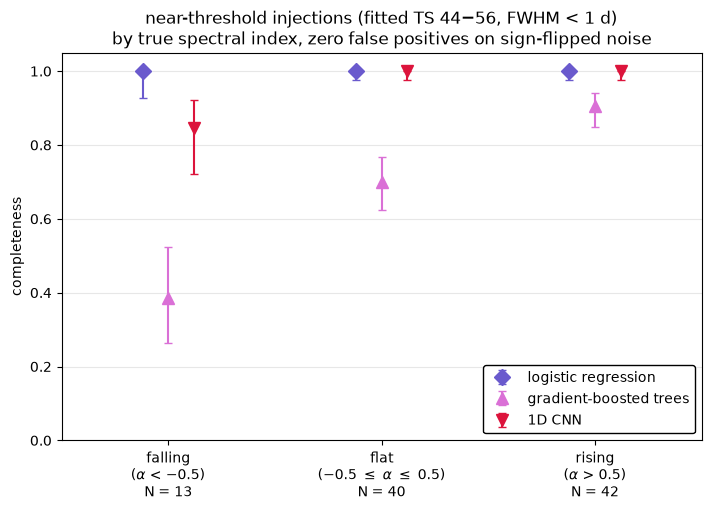

In [ ]:
# near-threshold injections (fitted TS 44-56, fitted FWHM < 1 d) split by their true injected spectral index,
# the same sample as the spectral prior check above, drawn for the three trained models
cnn_column = 'cnn_score' # the ensemble score column, rename if yours differs
spectral_methods = {'logistic': 'logistic_score', 'gbm': 'gbm_score', 'cnn': cnn_column}
spectrum_bins = {
    'falling\n($\\alpha$ < $-$0.5)': pl.col('inj_alpha') < -0.5,
    'flat\n($-$0.5 $\\leq$ $\\alpha$ $\\leq$ 0.5)': pl.col('inj_alpha').is_between(-0.5, 0.5),
    'rising\n($\\alpha$ > 0.5)': pl.col('inj_alpha') > 0.5,
}
noise_threshold = {column: noise[column].max() for column in spectral_methods.values()}
near_threshold_injections = positives_alpha.filter(pl.col('ts').is_between(44, 56), pl.col('fwhm_d') < 1)


def wilson_interval(k, n, z=1):
    """
    Wilson score interval for k successes in n trials (z = 1 for 1-sigma). Unlike the
    normal approximation, it stays inside [0, 1] and doesn't collapse to zero width at 0/n or n/n.
    """
    p = k / n
    center = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return center - half, center + half


bin_counts = [near_threshold_injections.filter(in_bin).height for in_bin in spectrum_bins.values()]
x = np.arange(len(spectrum_bins))

fig, ax = plt.subplots(figsize=(7, 5), layout='constrained')
for (name, column), offset in zip(spectral_methods.items(), [-0.12, 0, 0.12]):
    style = pltfun.METHOD_STYLES[name]
    fraction, low, high = [], [], []
    for in_bin in spectrum_bins.values():
        detected = near_threshold_injections.filter(in_bin)[column].to_numpy() > noise_threshold[column]
        interval = wilson_interval(detected.sum(), len(detected))
        fraction.append(detected.mean())
        low.append(interval[0])
        high.append(interval[1])
    fraction = np.array(fraction)
    ax.errorbar(x + offset, fraction, yerr=[fraction - np.array(low), np.array(high) - fraction],
                fmt=style['marker'], ms=8, capsize=3, color=style['color'], ls='none', label=style['label'])

ax.set_xticks(x, labels=[f"{label}\nN = {n}" for label, n in zip(spectrum_bins, bin_counts)])
ax.set_xlim(-0.5, len(spectrum_bins) - 0.5)
ax.set_ylim(0, 1.05)
ax.set_ylabel('completeness')
ax.set_title('near-threshold injections (fitted TS 44$-$56, FWHM < 1 d)\nby true spectral index, zero false positives on sign-flipped noise')
ax.grid(axis='y', alpha=0.3)
ax.legend(loc='lower right', edgecolor='k', framealpha=1)
plt.savefig(f"{image_dir}/evaluation/spectral_bias.png", dpi=150, bbox_inches='tight')

#### real events

In [ ]:
# retrain the five seeds with the models saved (identical results; training is seeded)
model_dir = 'data/cnn_models'
saved_ensemble = pl.read_parquet('data/cnn_scores.parquet')
retrained = [cnn.cross_validate(window_sequences, sequence_rows, seed=s, model_dir=model_dir)[0]
             for s in seeds]
retrained_mean = np.mean([r['cnn_score'].to_numpy() for r in retrained], axis=0)
assert np.allclose(retrained_mean, saved_ensemble['cnn_score'].to_numpy())

# real event windows from the database, scored by the fold models that never saw the star
with db.connect() as conn:
    windows = seq.fetch_window_observations(conn)
    event_rows, event_window_sequences = seq.event_sequences(conn, windows, window_sequences.shape[2])
event_rows = event_rows.with_columns(pl.Series('cnn_score', cnn.ensemble_predict(
    event_window_sequences, event_rows['gaia_id'].to_numpy(), folds, model_dir, seeds)))
print('event windows:', event_rows.height)

# per event: best window, detected if above the CNN's zero-FP noise threshold
cnn_threshold = noise['cnn_score'].max()
event_results = (event_rows.group_by('gaia_id', 'spt_id', 'mjd', 'origin')
                 .agg(pl.col('cnn_score').max(), pl.len().alias('N_windows'))
                 .with_columns((pl.col('cnn_score') > cnn_threshold).alias('cnn_detected')))
print(event_results.group_by('origin').agg(pl.len().alias('N'), pl.col('cnn_detected').sum()))
print(event_results.filter(~pl.col('cnn_detected')).sort('cnn_score'))

fold 0: 19 epochs, best epoch 13, val loss 0.1669, N_train 14624, N_val 2644, 7.0 s
fold 1: 23 epochs, best epoch 17, val loss 0.1653, N_train 14749, N_val 2501, 8.4 s
fold 2: 18 epochs, best epoch 12, val loss 0.1661, N_train 14396, N_val 2606, 6.2 s
fold 3: 15 epochs, best epoch 9, val loss 0.1577, N_train 14663, N_val 2493, 5.5 s
fold 4: 22 epochs, best epoch 16, val loss 0.1724, N_train 14717, N_val 2539, 8.0 s
fold 0: 18 epochs, best epoch 12, val loss 0.1654, N_train 14638, N_val 2630, 6.7 s
fold 1: 23 epochs, best epoch 17, val loss 0.1832, N_train 14683, N_val 2567, 8.3 s
fold 2: 19 epochs, best epoch 13, val loss 0.1699, N_train 14437, N_val 2565, 6.8 s
fold 3: 18 epochs, best epoch 12, val loss 0.1631, N_train 14560, N_val 2596, 6.5 s
fold 4: 10 epochs, best epoch 4, val loss 0.1666, N_train 14670, N_val 2586, 3.8 s
fold 0: 8 epochs, best epoch 2, val loss 0.1638, N_train 14720, N_val 2548, 3.0 s
fold 1: 11 epochs, best epoch 5, val loss 0.1861, N_train 14632, N_val 2618, 4.0

  0%|          | 0/112 [00:00<?, ?it/s]

event windows: 223
shape: (2, 3)
┌────────────┬─────┬──────────────┐
│ origin     ┆ N   ┆ cnn_detected │
│ ---        ┆ --- ┆ ---          │
│ str        ┆ u32 ┆ u32          │
╞════════════╪═════╪══════════════╡
│ guns2026   ┆ 1   ┆ 1            │
│ tandoi2024 ┆ 111 ┆ 110          │
└────────────┴─────┴──────────────┘
shape: (1, 7)
┌─────────────────┬─────────────────┬──────────┬────────────┬───────────┬───────────┬──────────────┐
│ gaia_id         ┆ spt_id          ┆ mjd      ┆ origin     ┆ cnn_score ┆ N_windows ┆ cnn_detected │
│ ---             ┆ ---             ┆ ---      ┆ ---        ┆ ---       ┆ ---       ┆ ---          │
│ str             ┆ str             ┆ f64      ┆ str        ┆ f64       ┆ u32       ┆ bool         │
╞═════════════════╪═════════════════╪══════════╪════════════╪═══════════╪═══════════╪══════════════╡
│ 646354635018645 ┆ SPT-SV J212043. ┆ 59003.11 ┆ tandoi2024 ┆ 0.908102  ┆ 2         ┆ false        │
│ 4144            ┆ 7-543755        ┆          ┆           

In [ ]:
# same results as logistic, missing that one flare that something is wrong with the data (?)

#### fixed spectral index

In [ ]:
# fixed-alpha injections from the database (same draws at six alphas, combined-SNR normalization)
with db.connect() as conn:
    fixed_alpha_rows = db.query_df(conn, """
        SELECT w.gaia_id, w.window_start, i.*
        FROM injections i
        JOIN windows w USING (window_id)
        WHERE i.injection_set = 'fixed_alpha'
        ORDER BY i.inj_alpha, i.inj_id
    """)
print('fixed-alpha injections:', fixed_alpha_rows.height)

# the rebuilt light curves must reproduce the stored TS (check_rebuild wants a source column)
check = seq.check_rebuild(fixed_alpha_rows.with_columns(pl.lit('fixed_alpha').alias('source')), windows)
print('max abs TS difference:', check['abs_diff'].max())

# CNN ensemble scores, each injection scored by the fold models that never saw its host star
fixed_alpha_sequences = seq.build_sequences(fixed_alpha_rows, windows, max_len=window_sequences.shape[2])
fixed_alpha_rows = fixed_alpha_rows.with_columns(pl.Series('cnn_score', cnn.ensemble_predict(
    fixed_alpha_sequences, fixed_alpha_rows['gaia_id'].to_numpy(), folds, model_dir, seeds)))

# the other methods' stored scores, matched on (alpha, injection)
fixed_alpha_scores = ev.ts_scores(pl.read_parquet('data/fixed_alpha_test.parquet')).select(
    'inj_alpha', pl.col('inj_id').cast(pl.Int64),
    'ts_positive_fwhm_pixel_score', 'ts_positive_score', 'logistic_score', 'gbm_score')
fixed_alpha_rows = (fixed_alpha_rows.with_columns(pl.col('inj_id').cast(pl.Int64))
                    .join(fixed_alpha_scores, on=['inj_alpha', 'inj_id'], how='left'))
print('rows without stored scores:', fixed_alpha_rows['logistic_score'].null_count())

# detection rate by alpha at each method's zero-FP threshold (noise = ensemble mirrored negatives)
compare = ['ts_positive_fwhm_pixel_score', 'ts_positive_score', 'logistic_score', 'gbm_score', 'cnn_score']
print(fixed_alpha_rows.group_by('inj_alpha').agg(
    pl.len().alias('N'),
    *[(pl.col(m) > noise[m].max()).mean().alias(m.replace('_score', '')) for m in compare],
).sort('inj_alpha'))

fixed-alpha injections: 9993


  0%|          | 0/100 [00:00<?, ?it/s]

max abs TS difference: 0.0


  0%|          | 0/9993 [00:00<?, ?it/s]

rows without stored scores: 0
shape: (6, 7)
┌───────────┬──────┬────────────────────────┬─────────────┬──────────┬──────────┬──────────┐
│ inj_alpha ┆ N    ┆ ts_positive_fwhm_pixel ┆ ts_positive ┆ logistic ┆ gbm      ┆ cnn      │
│ ---       ┆ ---  ┆ ---                    ┆ ---         ┆ ---      ┆ ---      ┆ ---      │
│ f64       ┆ u32  ┆ f64                    ┆ f64         ┆ f64      ┆ f64      ┆ f64      │
╞═══════════╪══════╪════════════════════════╪═════════════╪══════════╪══════════╪══════════╡
│ -2.0      ┆ 1668 ┆ 0.532974               ┆ 0.696643    ┆ 0.702038 ┆ 0.643885 ┆ 0.685851 │
│ -1.0      ┆ 1665 ┆ 0.595195               ┆ 0.698498    ┆ 0.70991  ┆ 0.664865 ┆ 0.698498 │
│ 0.0       ┆ 1665 ┆ 0.622222               ┆ 0.699099    ┆ 0.712913 ┆ 0.695495 ┆ 0.711712 │
│ 1.0       ┆ 1666 ┆ 0.602641               ┆ 0.696879    ┆ 0.710084 ┆ 0.712485 ┆ 0.711285 │
│ 2.0       ┆ 1664 ┆ 0.545072               ┆ 0.697115    ┆ 0.704928 ┆ 0.719351 ┆ 0.701923 │
│ 3.0       ┆ 1665 ┆ 0.465

In [ ]:
# ok maybe it's not the same as the GBM spectral index preference. looks like the CNN is just latching on to the most common spectral index in the data (alpha=1)
# my interpretation is that it's less confident in what it doesn't know rather than a learned bias. 